<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import random

In [3]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [4]:
len(l)

10000

In [5]:
l[:5]

[10, 8, 11, 9, 9]

In [6]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0265
3     0.0569
4     0.0826
5     0.1097
6     0.1446
7     0.1693
8     0.1360
9     0.1094
10    0.0823
11    0.0564
12    0.0263
Name: count, dtype: float64


<Axes: >

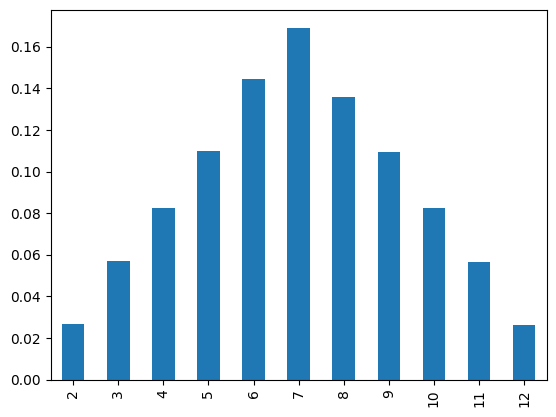

In [7]:
s.plot(kind='bar')

<Axes: >

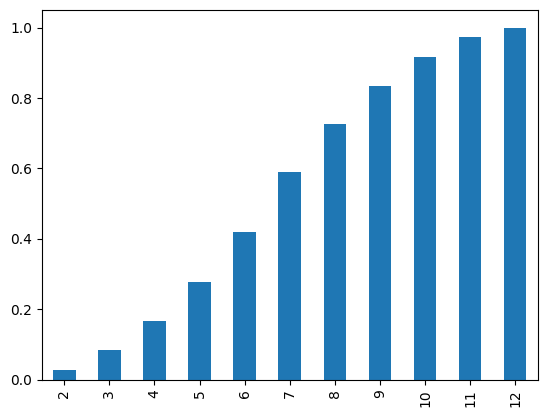

In [8]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [9]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[55.92703725 50.21911034 43.71094948 52.29986507 53.88474871 49.63426325
 50.02261963 48.04033295 46.48523006 47.41456259 52.08408528 49.22809481
 54.45194001 42.35330158 51.62494929 46.80503873 58.08171376 46.12339564
 51.26377221 43.4763006  56.10974135 50.26888347 43.36693613 47.1072256
 48.79220057 39.27083202 53.37405284 47.98577873 51.73481193 55.29905381
 54.81897382 51.68082102 42.46194628 52.71227513 50.46216937 52.46817306
 48.92633615 55.49526146 50.93741124 50.61154207 48.3297209  51.80816146
 47.64577913 45.32514186 40.50191817 50.12308122 47.13145504 52.89794408
 49.58994334 53.0796571  42.63797051 46.47913476 43.2705756  50.86664543
 56.11435238 58.00477702 46.31887934 42.571623   60.33983382 46.51100485
 57.21382148 54.01058831 53.23188351 57.05056207 47.33589991 42.21471074
 53.67246174 54.95202457 46.23673751 49.19437531 53.94950141 50.96779309
 54.78293353 47.0015607  54.98527708 41.71345322 50.93785981 47.90155372
 54.16960482 53.76124111 45.74066481 43.4952145  47.

In [10]:
sample.mean()

np.float64(49.86697471409086)

(array([  3.,  14.,  55., 141., 254., 256., 175.,  82.,  17.,   3.]),
 array([32.47918027, 35.86800683, 39.2568334 , 42.64565996, 46.03448652,
        49.42331309, 52.81213965, 56.20096622, 59.58979278, 62.97861934,
        66.36744591]),
 <BarContainer object of 10 artists>)

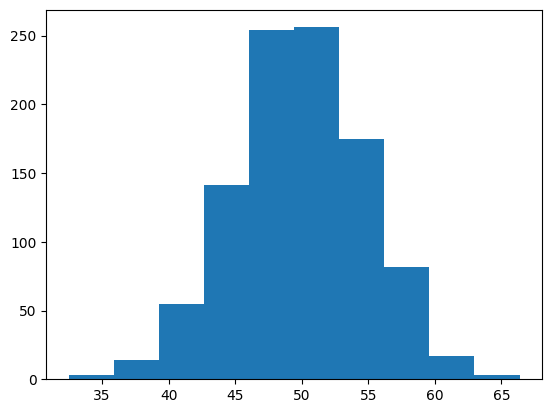

In [11]:
plt.hist(sample,bins=10)

In [12]:
sample_mean=sample.mean()
sample_std=sample.std()

In [13]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [14]:
sample.min()

np.float64(32.47918026872941)

In [15]:
sample.max()

np.float64(66.3674459081586)

In [16]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [17]:
probabilities=[dist.pdf(value) for value in values]

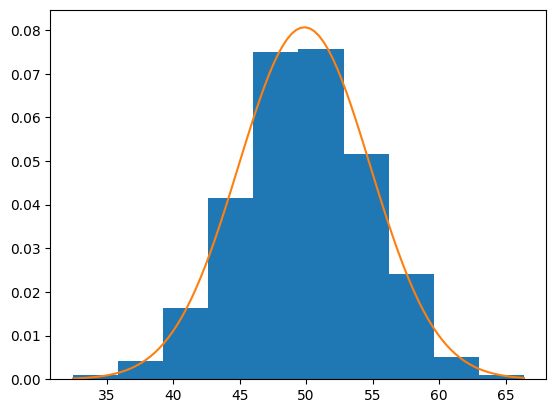

In [18]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_1078/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

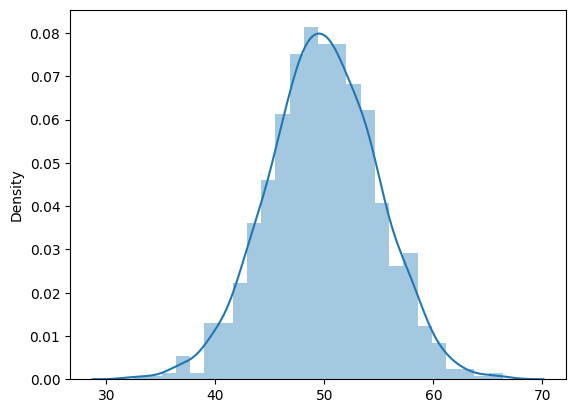

In [19]:
import seaborn as sns
sns.distplot(sample)

KDE

In [20]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [21]:
sample

array([21.34538122, 19.49978985, 17.81219211, 20.53687317, 18.65666198,
       18.29047071, 15.72830968, 13.96437504, 17.48813592, 17.63593265,
       22.09065438, 18.2776482 , 25.43157328, 23.04389298, 12.11845063,
       22.23794208, 12.82097076, 10.46300392, 13.94461796, 28.15758469,
       19.08177201, 11.9548933 , 20.17632447,  9.83382585, 24.44302746,
       21.49891812, 16.33620442, 17.59233055, 25.52488995, 22.44930308,
       13.32300866, 15.40092996, 20.78360801, 22.47014161,  6.43366176,
       21.66667663, 23.55395748, 23.06275914, 13.57716664, 32.33970284,
       10.84871306, 24.41303777, 12.91525943,  6.49631801, 18.61577955,
       11.74735763, 16.69343389, 17.59313563, 24.68470055, 25.26011438,
       15.00077317, 24.08162423, 15.69496552, 23.74867212, 21.73734357,
       20.56471193, 24.34627561, 23.46906865, 20.65298698, 16.16967087,
       14.87620223,  8.85896668, 20.40682836, 11.61915273, 18.22440314,
       22.10588946, 21.9002046 , 17.47504081, 26.93414435, 19.09

(array([ 3.,  1.,  3.,  3.,  4., 10.,  7., 11., 13., 11., 20., 20., 25.,
        20., 28., 23., 20., 16., 11., 20., 12., 14.,  8.,  9., 10., 11.,
        22., 32., 32., 37., 47., 41., 42., 54., 63., 53., 48., 43., 38.,
        33., 22., 15., 15., 12., 10.,  4.,  1.,  1.,  1.,  1.]),
 array([ 6.43366176,  7.41699898,  8.40033619,  9.38367341, 10.36701062,
        11.35034784, 12.33368505, 13.31702227, 14.30035949, 15.2836967 ,
        16.26703392, 17.25037113, 18.23370835, 19.21704556, 20.20038278,
        21.18371999, 22.16705721, 23.15039443, 24.13373164, 25.11706886,
        26.10040607, 27.08374329, 28.0670805 , 29.05041772, 30.03375494,
        31.01709215, 32.00042937, 32.98376658, 33.9671038 , 34.95044101,
        35.93377823, 36.91711544, 37.90045266, 38.88378988, 39.86712709,
        40.85046431, 41.83380152, 42.81713874, 43.80047595, 44.78381317,
        45.76715038, 46.7504876 , 47.73382482, 48.71716203, 49.70049925,
        50.68383646, 51.66717368, 52.65051089, 53.63384811,

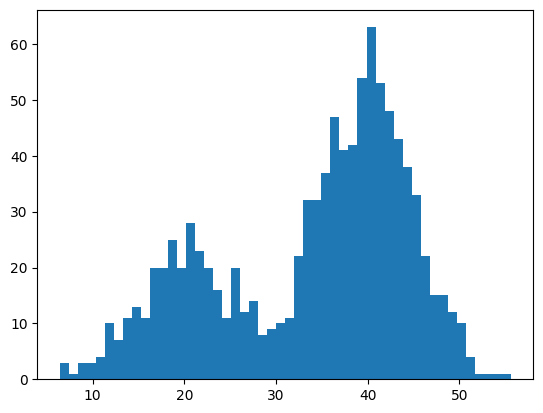

In [22]:
plt.hist(sample,bins=50)

In [23]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [24]:
dataset=sns.load_dataset("iris")

In [25]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

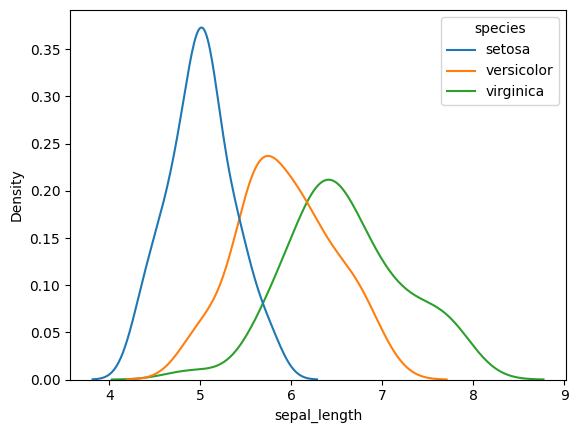

In [26]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

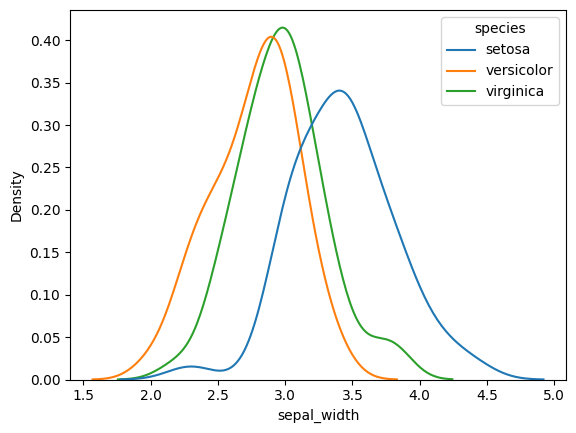

In [27]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

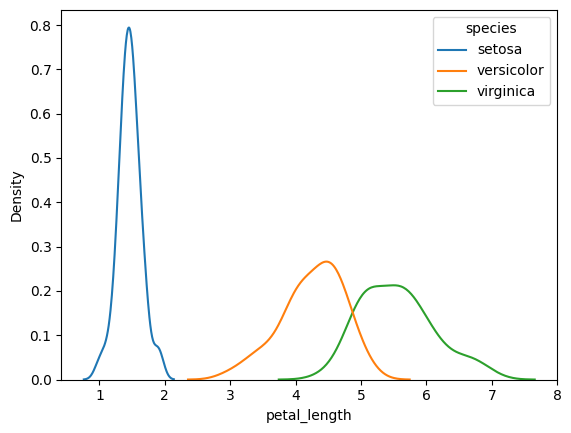

In [28]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

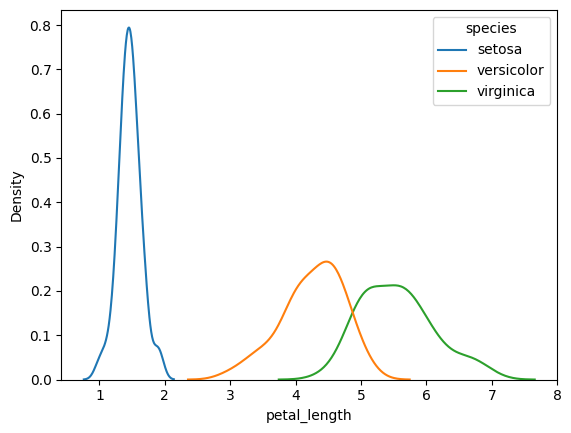

In [29]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [30]:
tips=sns.load_dataset("tips")

In [31]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

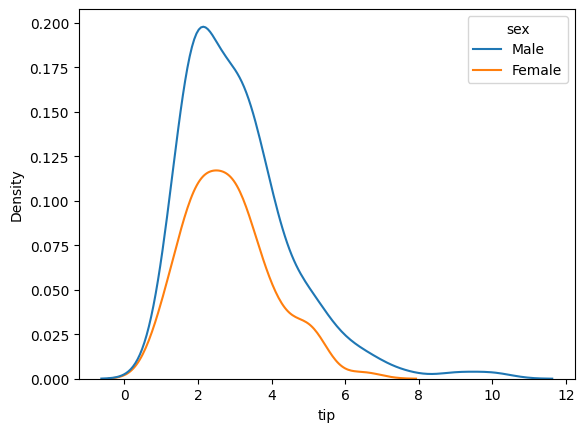

In [32]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

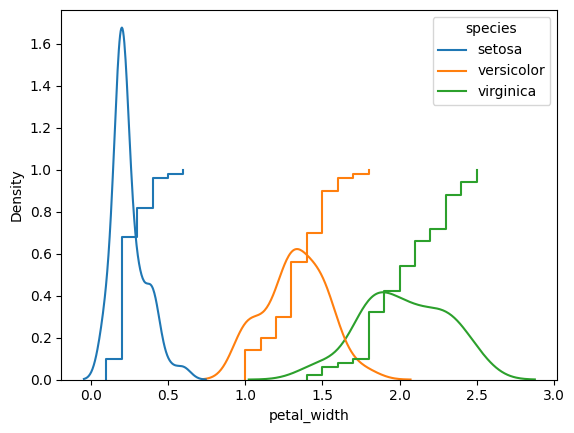

In [33]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [34]:
#contour plots

How to find distribution is normal or not?

In [35]:
iris=sns.load_dataset("iris")

<Axes: xlabel='sepal_length', ylabel='Density'>

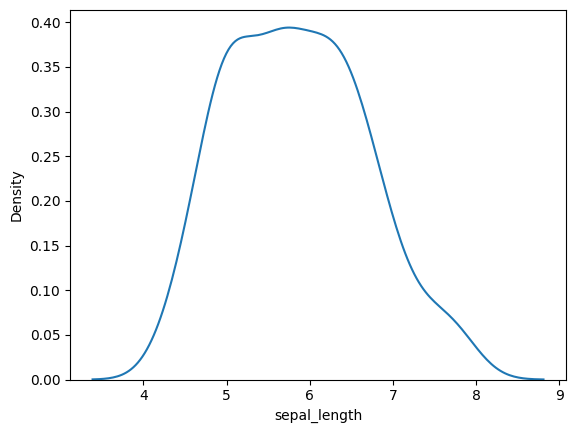

In [36]:
sns.kdeplot(iris["sepal_length"])

In [37]:
temp=sorted(iris['sepal_length'].tolist())

In [38]:
y_quant=[]

for i in range(1,101):
  y_quant.append(np.percentile(temp,i))

In [39]:
samples=np.random.normal(loc=0,scale=1,size=1000)

In [40]:
x_quant=[]

for i in range(1,101):
  x_quant.append(np.percentile(samples,i))

<Axes: >

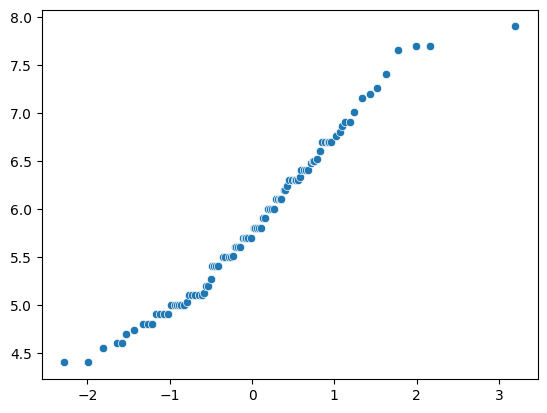

In [41]:
sns.scatterplot(x=x_quant,y=y_quant)

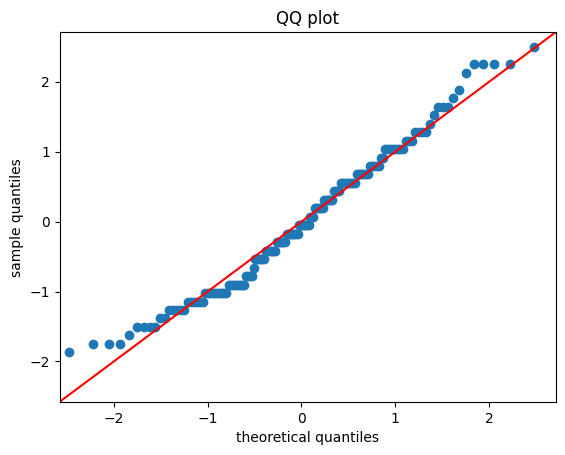

In [42]:
#using statsmodel

import statsmodels.api as sm

#create QQplot of two sets of data
fig=sm.qqplot(iris['sepal_length'],line='45',fit=True)

plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [43]:
import scipy.stats as stats

In [44]:
#genertate a set of random data
x=np.random.uniform(low=0,high=1,size=1000)

(array([ 84.,  95.,  90., 106.,  98.,  90., 120.,  96., 119., 102.]),
 array([0.00109807, 0.10081016, 0.20052225, 0.30023434, 0.39994643,
        0.49965852, 0.59937061, 0.6990827 , 0.79879479, 0.89850688,
        0.99821898]),
 <BarContainer object of 10 artists>)

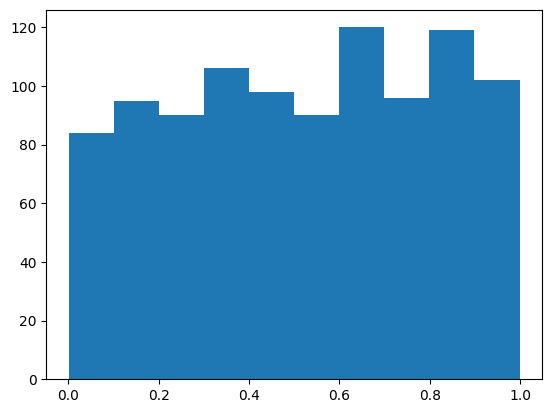

In [45]:
plt.hist(x)

PARETO DISTRIBUTION

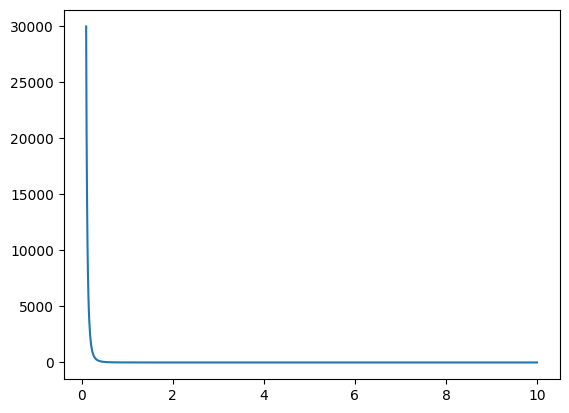

In [46]:
# DEFINE PARAMETERS OF Pareto distribution

alpha=3
xm=1

# create an array of x variables
x=np.linspace(0.1,10,1000)

#calculate teh y values of the pareto distribution
y=alpha*(xm**alpha)/(x**(alpha+1))

plt.plot(x,y)

Text(0.5, 1.0, 'Pareto distribution')

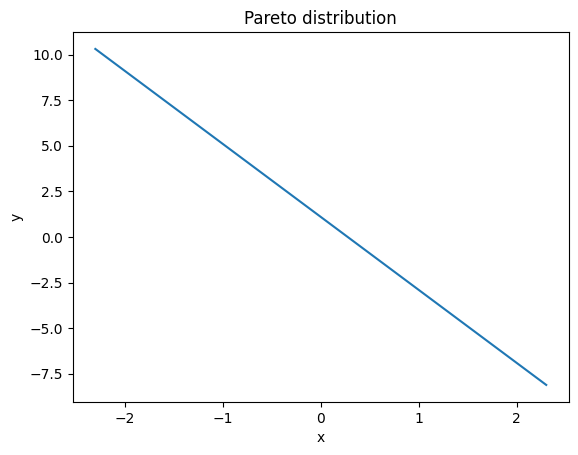

In [47]:
#calculate the log-log plot
plt.plot(np.log(x),np.log(y))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pareto distribution")

In [48]:
alpha =2
xm=1

x=stats.pareto.rvs(b=alpha,scale=xm,size=1000)

(array([997.,   2.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.]),
 array([  1.00088712,  13.73354769,  26.46620825,  39.19886882,
         51.93152939,  64.66418996,  77.39685053,  90.1295111 ,
        102.86217167, 115.59483224, 128.32749281]),
 <BarContainer object of 10 artists>)

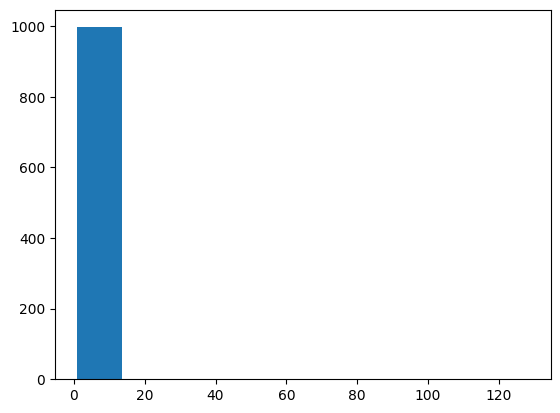

In [49]:
plt.hist(x)

In [50]:
params=stats.pareto.fit(x,floc=0)

#create a pareto distribution object with the fitted parameters
dist=stats.pareto(b=params[0],scale=params[2])

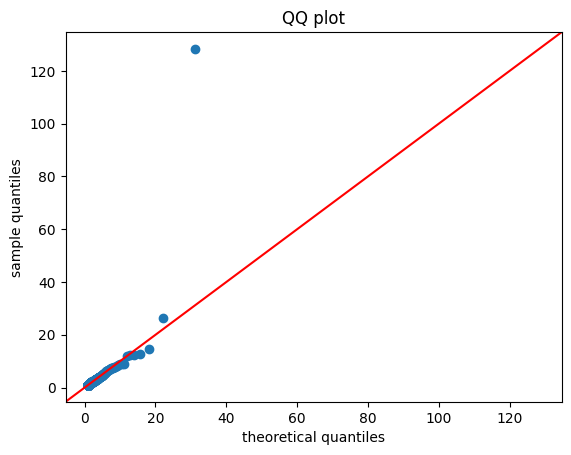

In [51]:
fig=sm.qqplot(x,line='45',dist=dist)
plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [52]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url,usecols=['Battery Age','Cycle Count','Daily Usage Hours'])

df.head()

,Battery Age,Daily Usage Hours,Cycle Count
0,5,9.797617,1267
1,9,7.101557,1500
2,9,10.085255,1500
3,5,7.946047,1153
4,7,9.628460,1500


In [53]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Cycle Count,0.952206


In [54]:
from scipy.stats import stats
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [55]:
df.isnull().sum()
# if missing values use df['column'].fillna(df['column'].mean(),inplace=True)

,0
Battery Age,0
Daily Usage Hours,0
Cycle Count,0


In [56]:
x=df.iloc[:,1:4]
y=df.iloc[:,0]

In [57]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)
'''What does train_test_split() do?
train_test_split() is a function from sklearn.model_selection that divides your dataset into two parts:
- Training data: Used to train the machine-learning model.
- Testing data: Used to check how well the model performs on data it hasn't trained on.

random_state=42 is optional. It makes the random split reproducible, so you get the same split when you run the code again with the same data.'''

"What does train_test_split() do?\ntrain_test_split() is a function from sklearn.model_selection that divides your dataset into two parts:\n- Training data: Used to train the machine-learning model.\n- Testing data: Used to check how well the model performs on data it hasn't trained on.\n\nrandom_state=42 is optional. It makes the random split reproducible, so you get the same split when you run the code again with the same data."

/tmp/ipykernel_1078/1170598051.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Daily Usage Hours'])


Text(0.5, 1.0, 'Daily Usage Hours QQ plot')

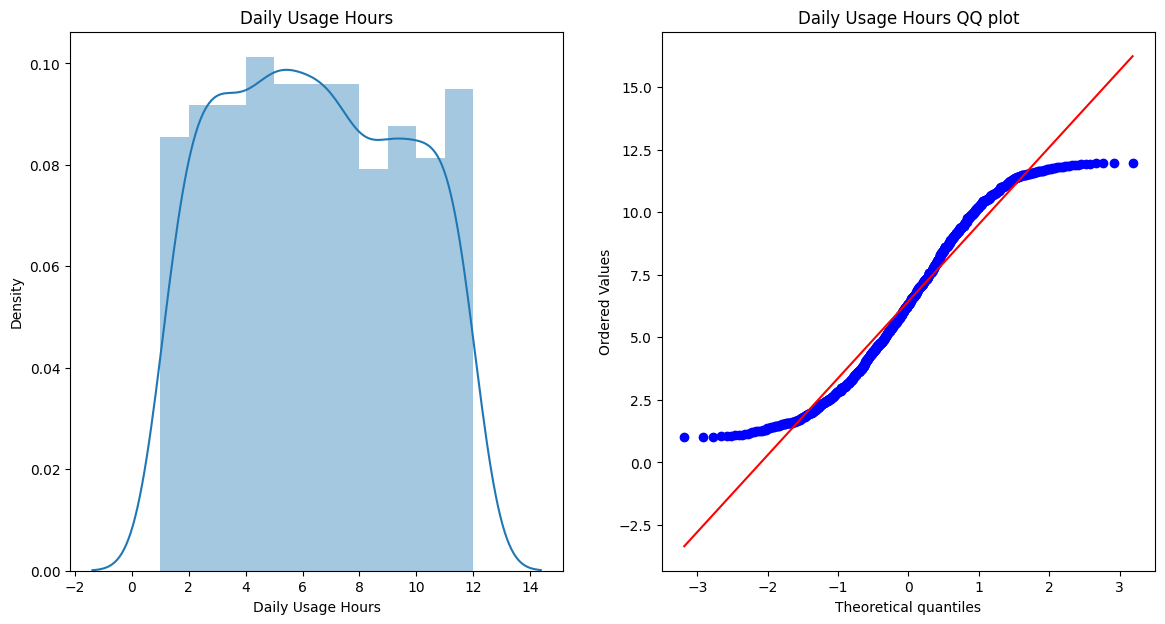

In [58]:
import scipy.stats as stats

plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Daily Usage Hours'])
plt.title("Daily Usage Hours")
plt.subplot(122)
stats.probplot(x_train['Daily Usage Hours'],dist="norm",plot=plt)
plt.title("Daily Usage Hours QQ plot")

/tmp/ipykernel_1078/882698.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Cycle Count'])


Text(0.5, 1.0, 'Cycle Count QQ plot')

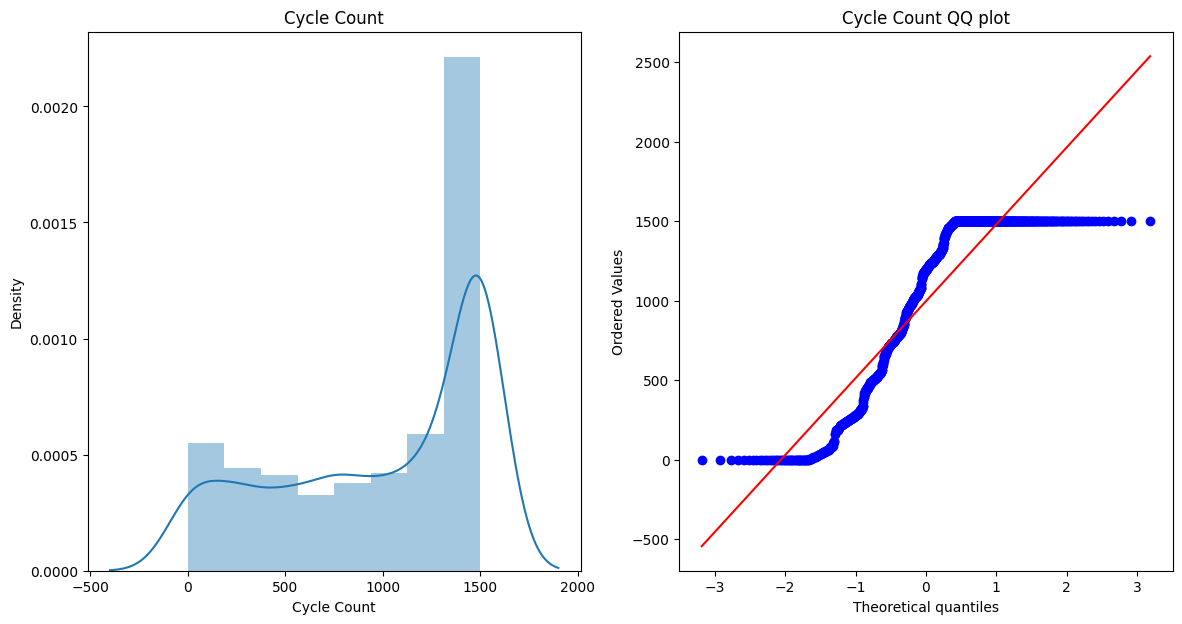

In [59]:
plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Cycle Count'])
plt.title("Cycle Count")
plt.subplot(122)
stats.probplot(x_train['Cycle Count'],dist="norm",plot=plt)
plt.title("Cycle Count QQ plot")


In [60]:
clf1=LogisticRegression()
clf2=DecisionTreeClassifier()

In [61]:
print(y.value_counts())
print(x.shape, y.shape)

Battery Age
5    145
3    134
9    130
7    126
6    123
0    113
2    112
1    109
4    107
8    101
Name: count, dtype: int64
(1200, 2) (1200,)


In [62]:
print(x.head())
print(y.head())
print(x.nunique())

   Daily Usage Hours  Cycle Count
0           9.797617         1267
1           7.101557         1500
2          10.085255         1500
3           7.946047         1153
4           9.628460         1500
0    5
1    9
2    9
3    5
4    7
Name: Battery Age, dtype: int64
Daily Usage Hours    1200
Cycle Count           562
dtype: int64


In [63]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Cycle Count,0.952206


In [64]:
clf1.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred=clf1.predict(x_test)
y_pred2=clf2.predict(x_test)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.2875
Accuracy DT 0.7041666666666667


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [65]:
trf=FunctionTransformer(np.log1p)

In [66]:
x_train_transform=trf.fit_transform(x_train)
x_test_transform=trf.transform(x_test)

print(x_train_transform)
print(x_test_transform)

     Daily Usage Hours  Cycle Count
500           2.519757     7.011214
397           2.560140     7.163947
377           1.887925     7.313887
509           1.413953     6.888572
869           2.162210     7.098376
..                 ...          ...
346           1.755270     3.401197
607           2.241913     5.521461
379           0.694395     7.313887
146           2.109158     7.313887
313           2.294979     6.173786

[960 rows x 2 columns]
      Daily Usage Hours  Cycle Count
84             2.246333     6.726233
722            2.495343     7.313887
785            2.036294     6.502790
789            1.815939     6.951772
580            1.962261     7.313887
...                 ...          ...
21             1.925732     6.129050
400            1.408210     6.943122
92             2.558595     6.104793
610            1.779486     7.313887
1057           1.552645     6.352629

[240 rows x 2 columns]


In [67]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

clf.fit(x_train_transform,y_train)
clf2.fit(x_train_transform,y_train)

y_pred=clf.predict(x_test_transform)
y_pred2=clf2.predict(x_test_transform)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.5916666666666667
Accuracy DT 0.7041666666666667


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


PDF of binomial ditribution.

[ 5  6  4  5  4  6  4  5  6  7  7  6  5  4  6  4  3  5  4  2  4  4  4  4
  5  6  5  3  4  4  5  7  0  5  7  6  4  6  5  7  5  6  3  6  7  6  6  6
  7  8  8  7  3  3  4  5  6  5  3  5  3  2  2  6  4  6  6  4  5  5  5  4
  6  6  2  3  3  4  5  4  8  5  4  4  4  6  5  5  5  6  5  4  4  7  2  5
  4  7  4  6  6  6  5  6  5  6  3  6  6  5  5  8  4  7  5  5  7  7  3  2
  4  2  4  7  7 10  4  5  3  6  4  5  5  5  5  8  4  4  1  7  8  4  5  5
  3  3  5  5  8  7  4  7  5  5  6  6  5  6  4  7  6  2  8  4  5  4  4  3
  4  2  5  5  1  5  2  5  3  7  5  3  7  6  5  6  3  7  5  6  5  5  6  6
  7  4  8  8  3  5  5  7  3  6  6  6  6  5  3  6  5  7  3  5  6  5  4  6
  6  7  2  5  9  3  8  6  5  6  6  7  3  6  6  5  6  7  4  4  5  5  4  7
  6  3  8  5  4  4  5  2  6  7  3  3  4  5  6  7  4  5  9  4  6  4  5  4
  6  6  6  7  3  4  5  8  5  6  5  5  5  4  3  8  5  4  5  6  6  4  5  2
  5  3  2  5  2  3  7  5  6  6  6  6  3  4  5  7  4  4  6  7  5  4  4  7
  6  6  7  7  6  4  7  7  4  4  5  5  6  7  7  3  7

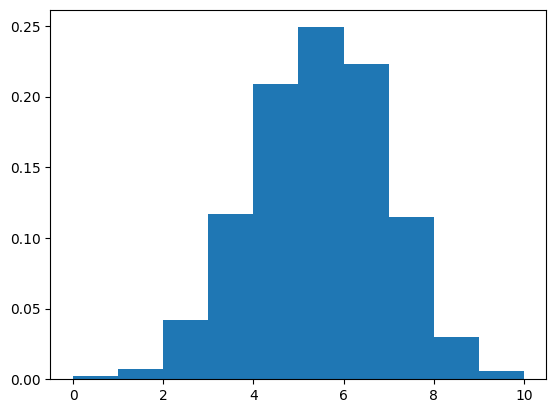

In [81]:
n=10    #number of trials
probability=0.5
binomial_d=np.random.binomial(n=n,p=probability,size=1000)
print(binomial_d)
plt.hist(binomial_d,density=True)
plt.show()
# when probability of success is less left skewed graph and vice versa

Central limit theorem

In [120]:
num_sample=100000
sample_size=300
dist_range=(0,1)

samples=np.random.uniform(dist_range[0],dist_range[1],(num_sample,sample_size))
samples.shape

(100000, 300)

In [121]:
sample_mean=np.mean(samples,axis=1)
sample_mean

array([0.51669494, 0.49281133, 0.49803387, ..., 0.49738038, 0.49823943,
       0.45892893])

In [122]:
sample_mean.shape

(100000,)

Text(0.5, 1.0, 'histogram of sample means')

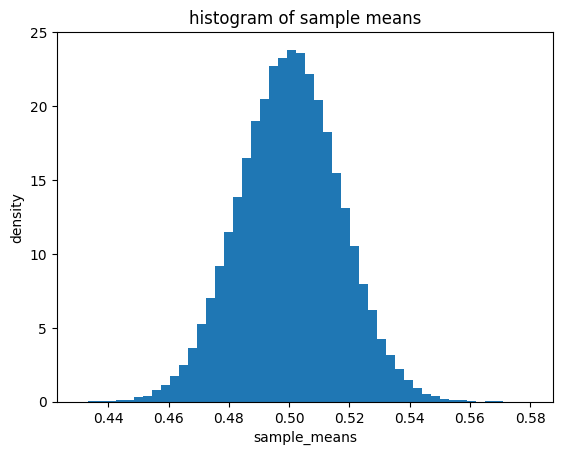

In [124]:
plt.hist(sample_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of sample means")

# greater the number of samples ,gratere is the chances of normal distribution

Different different distributions.

In [126]:
sample_nums=10000
sample_size=50

#poisson distribution parameters
poisson_lambda=5

#gamma distribution parameters
gamma_shape=2
gamma_scale=1

#binomial distribution parameters
binomial_n=10
binomial_p=0.5

# generation
poisson_d=np.random.poisson(lam=poisson_lambda,size=(sample_nums,sample_size))
gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(sample_nums,sample_size))
binomial_d=np.random.binomial(n=binomial_n,p=binomial_p,size=(sample_nums,sample_size))

#calculate means
poisson_mean=np.mean(poisson_d,axis=1)
gamma_mean=np.mean(gamma_d,axis=1)
binomial_mean=np.mean(binomial_d,axis=1)


Text(0.5, 1.0, 'histogram of biomial means')

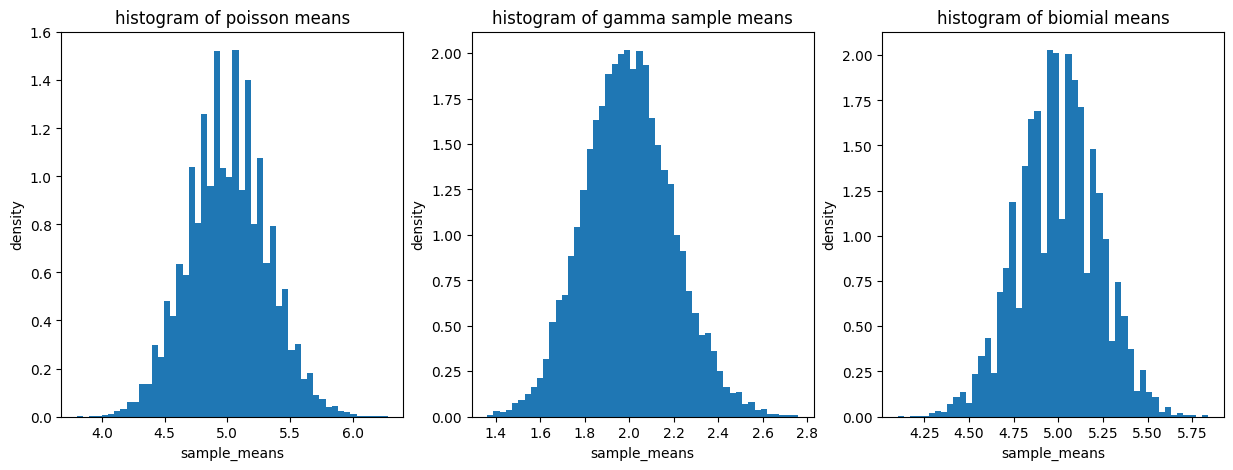

In [136]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1,)
plt.hist(poisson_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of poisson means")

plt.subplot(1,3,2)
plt.hist(gamma_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of gamma sample means")

plt.subplot(1,3,3)
plt.hist(binomial_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of biomial means")

In [138]:
gamma_samples=1000
gamma_size=30

gamma_shape=2
gamma_scale=1

theorotical_mean=gamma_shape*gamma_scale
theorotical_var=(gamma_shape*gamma_scale**2)

gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(gamma_samples,gamma_size))

gamma_means=np.mean(gamma_d,axis=1)
emperical_mean=np.mean(gamma_means)
emperical_var=np.var(gamma_means)

print("Theorotical mean:",theorotical_mean)
print("Theorotical variance:",theorotical_var)
print("Emperical mean:",emperical_mean)
print("Emperical variance:",emperical_var)


Theorotical mean: 2
Theorotical variance: 2
Emperical mean: 2.0019426432372422
Emperical variance: 0.07242688156565102
